## Forecasting Irish Day-Ahead Electricity Prices

### Part 1: Forecasts next-day half-hourly prices in the Single Electricity Market (SEM) day-ahead auction, using one year of SEMO results.

**Pipeline:** extract (SEMO via `irish-electricity-data`) → store (local + Azure Blob) → quality checks → leakage-safe features → baselines → models → test-set evaluation → rolling backtest → trading-value check.

In [1]:
%pip install irish-electricity-data

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import irish_electricity_data

print("Package imported successfully!")

Package imported successfully!


In [3]:
import datetime as dt
import inspect
import pandas as pd
import time
import json
from pathlib import Path

from irish_electricity_data import MarketClient, Auction

print("MarketClient imported successfully")
print("Auction options:", list(Auction))

MarketClient imported successfully
Auction options: [<Auction.DAY_AHEAD: 'DAY_AHEAD'>, <Auction.IDA1: 'IDA1'>, <Auction.IDA2: 'IDA2'>, <Auction.IDA3: 'IDA3'>]


In [4]:

DATA_DIR = Path("auction_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

In [5]:
with MarketClient() as client:
    method = client.semo.get_auction_results

    print("Method signature:")
    print(inspect.signature(method))

    print("\nMethod documentation:")
    print(inspect.getdoc(method))

print("\nAvailable auction types:")
print(list(Auction))

Method signature:
(auction: 'Auction', start_date: 'dt.date', end_date: 'dt.date | None' = None) -> 'AuctionResult'

Method documentation:
Get auction results by delivery date, inclusive on both ends.

Pads `date_to` by +1 day at the API layer to cover the 10:00-UTC filter
quirk, then client-side filters and de-duplicates to the latest
`publish_time` per delivery date. Multiple days are merged into one AuctionResult.

Available auction types:
[<Auction.DAY_AHEAD: 'DAY_AHEAD'>, <Auction.IDA1: 'IDA1'>, <Auction.IDA2: 'IDA2'>, <Auction.IDA3: 'IDA3'>]


In [6]:
test_date = dt.date(2026, 10, 12)

with MarketClient() as client:
    auction_result = client.semo.get_auction_results(
        Auction.DAY_AHEAD,
        test_date)

print("Returned type:", type(auction_result))
print("Returned object:")
print(repr(auction_result)[:5000])

Returned type: <class 'irish_electricity_data.providers.semo.models.AuctionResult'>
Returned object:
AuctionResult(price_eur=[DataPoint(timestamp=datetime.datetime(2026, 10, 11, 22, 0, tzinfo=datetime.timezone.utc), value=188.74), DataPoint(timestamp=datetime.datetime(2026, 10, 11, 22, 30, tzinfo=datetime.timezone.utc), value=184.37), DataPoint(timestamp=datetime.datetime(2026, 10, 11, 23, 0, tzinfo=datetime.timezone.utc), value=180.23), DataPoint(timestamp=datetime.datetime(2026, 10, 11, 23, 30, tzinfo=datetime.timezone.utc), value=176.06), DataPoint(timestamp=datetime.datetime(2026, 10, 12, 0, 0, tzinfo=datetime.timezone.utc), value=173.12), DataPoint(timestamp=datetime.datetime(2026, 10, 12, 0, 30, tzinfo=datetime.timezone.utc), value=173.0), DataPoint(timestamp=datetime.datetime(2026, 10, 12, 1, 0, tzinfo=datetime.timezone.utc), value=178.38), DataPoint(timestamp=datetime.datetime(2026, 10, 12, 1, 30, tzinfo=datetime.timezone.utc), value=181.95), DataPoint(timestamp=datetime.dateti

In [7]:
# Retrieve approximately one year of historical results
END_DATE = dt.date(2026, 10, 13)
START_DATE = END_DATE - dt.timedelta(days=364)

print(f"Extracting day-ahead results: {START_DATE} to {END_DATE}")

# Retrieve the day-ahead auction results
with MarketClient() as client:
    auction_result = client.semo.get_auction_results(
        Auction.DAY_AHEAD,
        START_DATE,
        END_DATE)

# Convert the result object into a dictionary
if hasattr(auction_result, "model_dump"):
    raw_data = auction_result.model_dump(mode="json")
else:
    raw_data = vars(auction_result)

# Save the unmodified result locally
raw_path = DATA_DIR / "day_ahead_auction_results_raw.json"

with raw_path.open("w", encoding="utf-8") as file:
    json.dump(raw_data, file, indent=2, ensure_ascii=False, default=str)

print("Raw data saved:", raw_path.resolve())
print("Available fields:", list(raw_data.keys()))

Extracting day-ahead results: 2025-10-14 to 2026-10-13
Raw data saved: C:\Users\mirac\Documents\Portfolio\auction_data\day_ahead_auction_results_raw.json
Available fields: ['price_eur', 'price_gbp', 'ni_volumes', 'ni_net_position', 'roi_volumes', 'roi_net_position']


In [8]:
# Convert each timestamp-value list into a named Series
def observations_to_series(observations, field_name):
    series = pd.DataFrame(observations)

    if series.empty:
        return pd.Series(dtype="float64", name=field_name)

    series["timestamp"] = pd.to_datetime(
        series["timestamp"], utc=True, errors="coerce")
    series["value"] = pd.to_numeric(series["value"], errors="coerce")

    series = series.dropna(subset=["timestamp"])
    series = series.drop_duplicates(
        subset=["timestamp"], keep="last")

    return series.set_index("timestamp")["value"].rename(field_name)


# Convert all available fields
series_list = []

for field_name, observations in raw_data.items():
    if isinstance(observations, list):
        series_list.append(
            observations_to_series(observations, field_name))

# Combine by timestamp
prices_df = pd.concat(series_list, axis=1).sort_index()
prices_df.index.name = "timestamp_utc"
prices_df = prices_df.reset_index()

# Save the forecasting dataset
csv_path = DATA_DIR / "irish_day_ahead_auction_results.csv"
prices_df.to_csv(csv_path, index=False)

print("CSV saved:", csv_path.resolve())
print("Dataset shape:", prices_df.shape)
display(prices_df.head())

CSV saved: C:\Users\mirac\Documents\Portfolio\auction_data\irish_day_ahead_auction_results.csv
Dataset shape: (17280, 7)


,timestamp_utc,price_eur,price_gbp,ni_volumes,ni_net_position,roi_volumes,roi_net_position
0,2025-10-18 22:00:00+00:00,35.61,30.93,1114.9,-244.8,4125.4,244.8
1,2025-10-18 22:30:00+00:00,16.00,13.90,1073.8,-162.5,4112.6,162.5
2,2025-10-18 23:00:00+00:00,23.32,20.26,1115.1,-227.1,4084.6,227.1
3,2025-10-18 23:30:00+00:00,22.40,19.46,1070.3,-135.7,4084.8,135.7
4,2025-10-19 00:00:00+00:00,33.00,28.67,1032.0,-127.6,4028.5,127.6


### 1. Data quality check

In [9]:
print(" FILE OVERVIEW ")
print(f"Rows: {len(prices_df):,}")
print("Columns:", prices_df.columns.tolist())

required = {"timestamp_utc", "price_eur"}
missing_columns = required - set(prices_df.columns)

if missing_columns:
    raise ValueError(f"Required columns missing: {sorted(missing_columns)}")

# Parse timestamps and prices
prices_df["timestamp_utc"] = pd.to_datetime(
    prices_df["timestamp_utc"], utc=True, errors="coerce")
prices_df["price_eur"] = pd.to_numeric(prices_df["price_eur"], errors="coerce")

invalid_timestamps = prices_df["timestamp_utc"].isna().sum()
prices_df = prices_df.dropna(subset=["timestamp_utc"]).sort_values("timestamp_utc")

print("\n TIMESTAMP COVERAGE")
print("Invalid timestamps:", invalid_timestamps)
print("First timestamp:", prices_df["timestamp_utc"].min())
print("Last timestamp: ", prices_df["timestamp_utc"].max())
print("Unique timestamps:", prices_df["timestamp_utc"].nunique())
print(
    "Calendar dates covered:",
    prices_df["timestamp_utc"].dt.date.nunique())

# Duplicate timestamps
duplicate_rows = prices_df["timestamp_utc"].duplicated(keep=False).sum()
print("\n DUPLICATES")
print("Rows involved in duplicate timestamps:", duplicate_rows)

# Stop before gap analysis if timestamps are duplicated.
# Resolve duplicates explicitly rather than silently discarding prices.
if duplicate_rows:
    print("WARNING: Resolve duplicate timestamps before modelling.")

# 4. Missing prices and price summary
print("\n PRICE QUALITY ")
print("Missing price values:", prices_df["price_eur"].isna().sum())
print("Infinite price values:", (~prices_df["price_eur"].dropna().map(
    lambda x: pd.notna(x) and abs(x) != float("inf")
)).sum())

print(prices_df["price_eur"].describe(
    percentiles=[0.01, 0.25, 0.50, 0.75, 0.99]))

print("Negative prices:", (prices_df["price_eur"] < 0).sum())
print("Zero prices:", (prices_df["price_eur"] == 0).sum())

# Timestamp intervals and gaps
timestamps = (
    prices_df["timestamp_utc"]
    .drop_duplicates()
    .sort_values())

intervals = timestamps.diff().dropna()
print("\n TIME INTERVALS ")
print("Most common intervals:")
print(intervals.value_counts().head(10))

if not intervals.empty:
    expected_interval = intervals.mode().iloc[0]
    print("Most common interval:", expected_interval)

    gaps = intervals[intervals > expected_interval]
    print("Intervals longer than the most common interval:", len(gaps))

    if len(gaps):
        gap_report = pd.DataFrame({
            "previous_timestamp": timestamps.iloc[
                intervals[intervals > expected_interval].index - 1
            ].to_list(),
            "gap": gaps.to_list(),
            "next_timestamp": timestamps.iloc[
                intervals[intervals > expected_interval].index
            ].to_list()
        })
        print("\nLargest gaps:")
        display(gap_report.sort_values("gap", ascending=False).head(20))

    # Estimate how many timestamps are absent on the dominant time grid.
    expected_grid = pd.date_range(
        start=timestamps.min(),
        end=timestamps.max(),
        freq=expected_interval)
    absent = expected_grid.difference(pd.DatetimeIndex(timestamps))

    print("\nExpected timestamps on dominant grid:", len(expected_grid))
    print("Absent timestamps on dominant grid:", len(absent))
    if len(absent):
        print("First absent timestamps:")
        display(pd.Series(absent[:20], name="absent_timestamp"))

# Other market variables
print("\n OTHER MARKET VARIABLES ")
for col in prices_df.columns:
    if col not in ["timestamp_utc", "price_eur"]:
        values = pd.to_numeric(prices_df[col], errors="coerce")
        print(
            f"{col}: {values.notna().sum():,} numeric values "
            f"out of {len(prices_df):,} rows")


 FILE OVERVIEW 
Rows: 17,280
Columns: ['timestamp_utc', 'price_eur', 'price_gbp', 'ni_volumes', 'ni_net_position', 'roi_volumes', 'roi_net_position']

 TIMESTAMP COVERAGE
Invalid timestamps: 0
First timestamp: 2025-10-18 22:00:00+00:00
Last timestamp:  2026-10-13 21:30:00+00:00
Unique timestamps: 17280
Calendar dates covered: 361

 DUPLICATES
Rows involved in duplicate timestamps: 0

 PRICE QUALITY 
Missing price values: 0
Infinite price values: 0
count    17280.00000
mean       137.84166
std         57.75235
min        -10.09000
1%           6.99160
25%         98.65500
50%        132.00000
75%        172.01000
99%        299.00000
max        465.77000
Name: price_eur, dtype: float64
Negative prices: 8
Zero prices: 56

 TIME INTERVALS 
Most common intervals:
timestamp_utc
0 days 00:30:00    17279
Name: count, dtype: int64
Most common interval: 0 days 00:30:00
Intervals longer than the most common interval: 0

Expected timestamps on dominant grid: 17280
Absent timestamps on dominant gr

### 2. Save Raw and Flattened Data to Azure Blob Storage

In [10]:
import os
from dotenv import load_dotenv
from azure.storage.blob import BlobServiceClient
from azure.core.credentials import AzureNamedKeyCredential
from azure.core.exceptions import ResourceNotFoundError

In [11]:
ROOT = Path.cwd()
load_dotenv(ROOT / "azure.env", override=True)

AZURE_STORAGE_ACCOUNT = os.getenv("AZURE_STORAGE_ACCOUNT")
AZURE_STORAGE_KEY = os.getenv("AZURE_STORAGE_KEY")
AZURE_STORAGE_CONTAINER = os.getenv("AZURE_STORAGE_CONTAINER", "electricity-price-forecast")

assert AZURE_STORAGE_ACCOUNT, "Missing AZURE_STORAGE_ACCOUNT in azure.env"
assert AZURE_STORAGE_KEY, "Missing AZURE_STORAGE_KEY in azure.env"

credential = AzureNamedKeyCredential(AZURE_STORAGE_ACCOUNT, AZURE_STORAGE_KEY)
account_url = f"https://{AZURE_STORAGE_ACCOUNT}.blob.core.windows.net"

blob_service = BlobServiceClient(account_url=account_url, credential=credential)
container = blob_service.get_container_client(AZURE_STORAGE_CONTAINER)

try:
    container.get_container_properties()
    print("Connected to existing container:", AZURE_STORAGE_CONTAINER)
except ResourceNotFoundError:
    container.create_container()
    print("Created container:", AZURE_STORAGE_CONTAINER)

Connected to existing container: electricity-price-forecast


In [12]:

# Upload raw_data as a JSON file
if 'raw_data' in locals():
    # default=str handles dates, datetimes, or custom objects if present
    raw_json = json.dumps(raw_data, indent=2, default=str)
    
    blob_client = container.get_blob_client("raw_data.json")
    blob_client.upload_blob(raw_json, overwrite=True)
    print("Successfully uploaded raw_data.json")
else:
    print("Error: 'raw_data' variable is not defined.")

# Upload prices_df as a CSV file
if 'prices_df' in locals():
    # Convert DataFrame to CSV string in memory
    csv_data = prices_df.to_csv(index=False)
    
    blob_client = container.get_blob_client("prices.csv")
    blob_client.upload_blob(csv_data, overwrite=True)
    print("Successfully uploaded prices.csv")
else:
    print("Error: 'prices_df' variable is not defined.")

Successfully uploaded raw_data.json
Successfully uploaded prices.csv


### 3. Forecasting setup
Task: each morning (day D, before the 11:00 day-ahead gate closure), forecast all half-hourly day-ahead prices for delivery day D+1.

What is known at forecast time: every auction result up to the end of delivery day D (published the previous afternoon). Nothing from D+1 is known.

In [13]:
%pip install holidays

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
import numpy as np

In [15]:
import holidays

model_df = prices_df.copy().sort_values("timestamp_utc").reset_index(drop=True)

# Demand follows the Irish clock, not UTC, so calendar features use local time
model_df["timestamp_local"] = model_df["timestamp_utc"].dt.tz_convert("Europe/Dublin")
local = model_df["timestamp_local"]

# SEM trading day runs 23:00-23:00 local; its delivery date is the local date one hour later
model_df["delivery_date"] = pd.to_datetime((local + pd.Timedelta(hours=1)).dt.date)

model_df["hour"] = local.dt.hour
model_df["minute"] = local.dt.minute
model_df["day_of_week"] = local.dt.dayofweek
model_df["month"] = local.dt.month
model_df["is_weekend"] = (model_df["day_of_week"] >= 5).astype(int)

ie_holidays = holidays.country_holidays("IE", years=range(local.dt.year.min(), local.dt.year.max() + 1))
model_df["is_holiday"] = local.dt.date.map(lambda d: int(d in ie_holidays))

minutes = model_df["hour"] * 60 + model_df["minute"]
model_df["time_of_day_sin"] = np.sin(2 * np.pi * minutes / 1440)
model_df["time_of_day_cos"] = np.cos(2 * np.pi * minutes / 1440)
doy = local.dt.dayofyear
model_df["day_of_year_sin"] = np.sin(2 * np.pi * doy / 365.25)
model_df["day_of_year_cos"] = np.cos(2 * np.pi * doy / 365.25)

# Leakage-safe price lags (>= 48 half-hours)
for lag in [48, 96, 144, 336]:
    model_df[f"price_lag_{lag}"] = model_df["price_eur"].shift(lag)

# Mean of the same half-hour over the previous 7 days
model_df["same_period_7d_mean"] = pd.concat(
    [model_df["price_eur"].shift(48 * k) for k in range(1, 8)], axis=1).mean(axis=1)

# Previous delivery day summary (all of day D is known when forecasting D+1)
daily = model_df.groupby("delivery_date")["price_eur"].agg(
    prev_day_mean="mean", prev_day_max="max", prev_day_min="min",
    prev_day_std="std", prev_day_last="last")
daily["prev_7day_mean"] = daily["prev_day_mean"].rolling(7, min_periods=7).mean()
daily.index = daily.index + pd.Timedelta(days=1)   # shift so D's stats attach to D+1
model_df = model_df.merge(daily, left_on="delivery_date", right_index=True, how="left")

# Lagged market volumes (previous day's auction outcome, so known)
for col in ["roi_volumes", "ni_volumes", "roi_net_position"]:
    model_df[f"{col}_lag_48"] = model_df[col].shift(48)

FEATURES = [
    "hour", "minute", "day_of_week", "is_weekend", "is_holiday", "month",
    "time_of_day_sin", "time_of_day_cos", "day_of_year_sin", "day_of_year_cos",
    "price_lag_48", "price_lag_96", "price_lag_144", "price_lag_336", "same_period_7d_mean",
    "prev_day_mean", "prev_day_max", "prev_day_min", "prev_day_std", "prev_day_last", "prev_7day_mean",
    "roi_volumes_lag_48", "ni_volumes_lag_48", "roi_net_position_lag_48",
]
TARGET = "price_eur"

safe_df = model_df.dropna(subset=FEATURES + [TARGET]).reset_index(drop=True)
print(f"Rows before/after dropping warm-up period: {len(model_df):,} / {len(safe_df):,}")
print("Features:", len(FEATURES))

model_path = DATA_DIR / "irish_day_ahead_model_data.csv"
safe_df.to_csv(model_path, index=False)
print("Saved:", model_path.resolve())


Rows before/after dropping warm-up period: 17,280 / 16,944
Features: 24
Saved: C:\Users\mirac\Documents\Portfolio\auction_data\irish_day_ahead_model_data.csv


#### 3i. Time-based split
 Chronological Splits made on whole delivery days, in time order. The last 8 weeks are the test set.

In [16]:

days = np.sort(safe_df["delivery_date"].unique())
TEST_DAYS, VAL_DAYS = 56, 56

test_start = days[-TEST_DAYS]
val_start = days[-(TEST_DAYS + VAL_DAYS)]

train = safe_df[safe_df["delivery_date"] < val_start]
val = safe_df[(safe_df["delivery_date"] >= val_start) & (safe_df["delivery_date"] < test_start)]
test = safe_df[safe_df["delivery_date"] >= test_start]

for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:<11} {part['delivery_date'].min().date()} to {part['delivery_date'].max().date()}"
          f"  | {part['delivery_date'].nunique():>3} days | {len(part):>6,} rows")

Train       2025-10-26 to 2026-06-23  | 241 days | 11,568 rows
Validation  2026-06-24 to 2026-08-18  |  56 days |  2,688 rows
Test        2026-08-19 to 2026-10-13  |  56 days |  2,688 rows


In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate(y_true, y_pred, frame, name, naive_mae=None):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    peak = frame["hour"].between(17, 19).to_numpy()   # local evening peak 17:00-19:59
    mae = mean_absolute_error(y_true, y_pred)
    out = {
        "model": name,
        "MAE": mae,
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "peak_MAE": mean_absolute_error(y_true[peak], y_pred[peak]),
        "bias": np.mean(y_pred - y_true),
    }
    if naive_mae is not None:
        out["skill_vs_naive"] = 1 - mae / naive_mae   # >0 means better than "same as yesterday"
    return out

#### 3ii. Baselines


In [18]:
baseline_cols = {
    "Naive: same period yesterday": "price_lag_48",
    "Naive: same period last week": "price_lag_336",
    "Naive: 7-day same-period mean": "same_period_7d_mean",}

naive_val_mae = mean_absolute_error(val[TARGET], val["price_lag_48"])
val_results = [evaluate(val[TARGET], val[col], val, name, naive_val_mae)
               for name, col in baseline_cols.items()]
pd.DataFrame(val_results).round(2)

,model,MAE,RMSE,peak_MAE,bias,skill_vs_naive
0,Naive: same period yesterday,30.75,42.37,34.20,0.34,0.00
1,Naive: same period last week,33.69,48.13,36.84,-3.65,-0.10
2,Naive: 7-day same-period mean,27.88,39.14,30.11,-1.38,0.09


#### 3iii. Models

**Ridge regression** and **Histogram gradient boosting** 

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CATEGORICAL = ["hour", "day_of_week"]
NUMERIC = [f for f in FEATURES if f not in CATEGORICAL]

def make_ridge(alpha=1.0):
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
        ("num", StandardScaler(), NUMERIC)])
    return make_pipeline(pre, Ridge(alpha=alpha))

def make_hgb(**params):
    return HistGradientBoostingRegressor(random_state=42, **params)

# Ridge
ridge = make_ridge(alpha=10.0).fit(train[FEATURES], train[TARGET])
val_results.append(evaluate(val[TARGET], ridge.predict(val[FEATURES]), val, "Ridge", naive_val_mae))

# Gradient boosting: small grid, chosen on validation MAE
grid = [
    dict(learning_rate=0.05, max_iter=500, max_leaf_nodes=31, min_samples_leaf=40),
    dict(learning_rate=0.05, max_iter=800, max_leaf_nodes=15, min_samples_leaf=80),
    dict(learning_rate=0.03, max_iter=1000, max_leaf_nodes=63, min_samples_leaf=40, l2_regularization=1.0),]
best_params, best_mae = None, np.inf
for params in grid:
    m = make_hgb(**params).fit(train[FEATURES], train[TARGET])
    mae = mean_absolute_error(val[TARGET], m.predict(val[FEATURES]))
    print(f"MAE {mae:6.2f}  {params}")
    if mae < best_mae:
        best_params, best_mae = params, mae

hgb = make_hgb(**best_params).fit(train[FEATURES], train[TARGET])
val_results.append(evaluate(val[TARGET], hgb.predict(val[FEATURES]), val, "Gradient boosting", naive_val_mae))

print("\nBest params:", best_params)
pd.DataFrame(val_results).sort_values("MAE").round(2)

MAE  24.64  {'learning_rate': 0.05, 'max_iter': 500, 'max_leaf_nodes': 31, 'min_samples_leaf': 40}
MAE  25.75  {'learning_rate': 0.05, 'max_iter': 800, 'max_leaf_nodes': 15, 'min_samples_leaf': 80}
MAE  24.09  {'learning_rate': 0.03, 'max_iter': 1000, 'max_leaf_nodes': 63, 'min_samples_leaf': 40, 'l2_regularization': 1.0}

Best params: {'learning_rate': 0.03, 'max_iter': 1000, 'max_leaf_nodes': 63, 'min_samples_leaf': 40, 'l2_regularization': 1.0}


,model,MAE,RMSE,peak_MAE,bias,skill_vs_naive
3,Ridge,22.87,32.44,26.70,3.14,0.26
4,Gradient boosting,24.09,33.88,29.13,0.54,0.22
2,Naive: 7-day same-period mean,27.88,39.14,30.11,-1.38,0.09
0,Naive: same period yesterday,30.75,42.37,34.20,0.34,0.00
1,Naive: same period last week,33.69,48.13,36.84,-3.65,-0.10


In [20]:
train_full = pd.concat([train, val])

ridge_final = make_ridge(alpha=10.0).fit(train_full[FEATURES], train_full[TARGET])
hgb_final = make_hgb(**best_params).fit(train_full[FEATURES], train_full[TARGET])

# Quantile models give a P10-P90 range: useful for risk, not just a point forecast
hgb_p10 = make_hgb(loss="quantile", quantile=0.10, **best_params).fit(train_full[FEATURES], train_full[TARGET])
hgb_p90 = make_hgb(loss="quantile", quantile=0.90, **best_params).fit(train_full[FEATURES], train_full[TARGET])

forecasts = test[["timestamp_utc", "timestamp_local", "delivery_date", "hour", TARGET]].copy()
forecasts["naive_d1"] = test["price_lag_48"]
forecasts["naive_d7"] = test["price_lag_336"]
forecasts["naive_7d_mean"] = test["same_period_7d_mean"]
forecasts["ridge"] = ridge_final.predict(test[FEATURES])
forecasts["hgb"] = hgb_final.predict(test[FEATURES])
forecasts["hgb_p10"] = hgb_p10.predict(test[FEATURES])
forecasts["hgb_p90"] = hgb_p90.predict(test[FEATURES])

naive_test_mae = mean_absolute_error(forecasts[TARGET], forecasts["naive_d1"])
model_names = {
    "naive_d1": "Naive: same period yesterday",
    "naive_d7": "Naive: same period last week",
    "naive_7d_mean": "Naive: 7-day same-period mean",
    "ridge": "Ridge",
    "hgb": "Gradient boosting",
}
test_results = pd.DataFrame([
    evaluate(forecasts[TARGET], forecasts[col], forecasts, name, naive_test_mae)
    for col, name in model_names.items()]).sort_values("MAE")

coverage = forecasts[TARGET].between(forecasts["hgb_p10"], forecasts["hgb_p90"]).mean()
print(f"P10-P90 interval coverage: {coverage:.1%} (target 80%)")
test_results.round(2)

P10-P90 interval coverage: 58.5% (target 80%)


,model,MAE,RMSE,peak_MAE,bias,skill_vs_naive
3,Ridge,34.51,48.08,35.10,-14.36,0.27
4,Gradient boosting,38.23,52.53,43.43,-14.88,0.19
2,Naive: 7-day same-period mean,38.90,55.86,37.83,0.78,0.17
0,Naive: same period yesterday,47.01,69.70,40.85,0.19,0.00
1,Naive: same period last week,48.95,70.19,49.26,1.72,-0.04


#### 4. Visuals for initial modelling

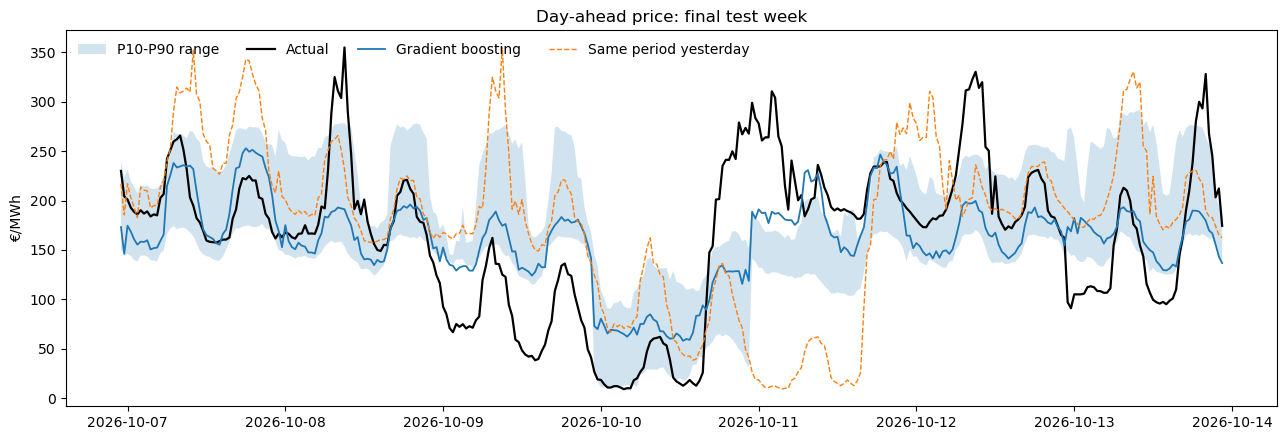

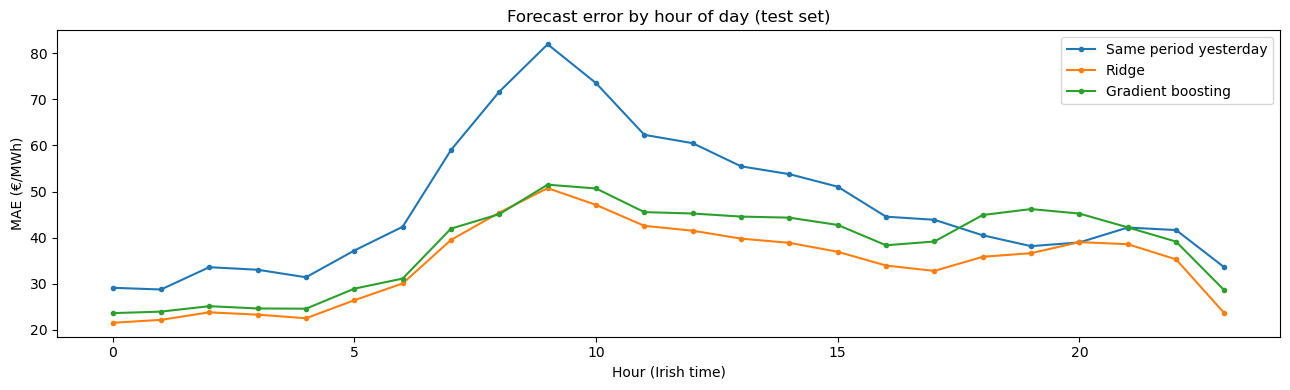

In [21]:
import matplotlib.pyplot as plt

# One week of forecasts against actuals
week = forecasts[forecasts["delivery_date"] >= forecasts["delivery_date"].max() - pd.Timedelta(days=6)]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.fill_between(week["timestamp_local"], week["hgb_p10"], week["hgb_p90"],
                alpha=0.2, label="P10-P90 range")
ax.plot(week["timestamp_local"], week[TARGET], color="black", lw=1.6, label="Actual")
ax.plot(week["timestamp_local"], week["hgb"], lw=1.3, label="Gradient boosting")
ax.plot(week["timestamp_local"], week["naive_d1"], lw=1, ls="--", label="Same period yesterday")
ax.set_ylabel("€/MWh")
ax.set_title("Day-ahead price: final test week")
ax.legend(loc="upper left", ncol=4, frameon=False)
plt.tight_layout()
plt.show()

# Where in the day are errors largest?
err_by_hour = pd.DataFrame({
    name: (forecasts[col] - forecasts[TARGET]).abs().groupby(forecasts["hour"]).mean()
    for col, name in [("naive_d1", "Same period yesterday"), ("ridge", "Ridge"), ("hgb", "Gradient boosting")]})
ax = err_by_hour.plot(figsize=(13, 4), marker="o", ms=3)
ax.set_xlabel("Hour (Irish time)")
ax.set_ylabel("MAE (€/MWh)")
ax.set_title("Forecast error by hour of day (test set)")
plt.tight_layout()
plt.show()


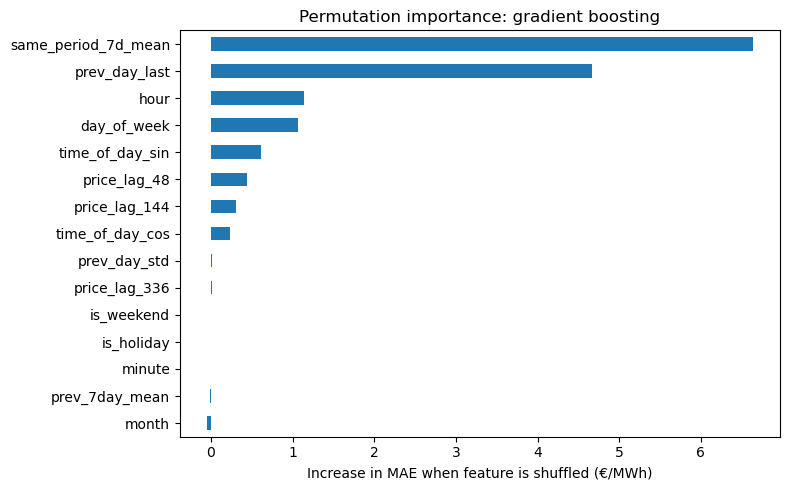

In [22]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(hgb_final, test[FEATURES], test[TARGET],
                             scoring="neg_mean_absolute_error", n_repeats=5, random_state=42)
importance = (pd.Series(imp.importances_mean, index=FEATURES)
              .sort_values(ascending=True).tail(15))

ax = importance.plot.barh(figsize=(8, 5))
ax.set_xlabel("Increase in MAE when feature is shuffled (€/MWh)")
ax.set_title("Permutation importance: gradient boosting")
plt.tight_layout()
plt.show()

### 5. Rolling backtest 

Here the model is retrained every week on all data available up to that point, then forecasts the following week.


In [23]:
test_days = np.sort(test["delivery_date"].unique())
weekly_rows = []

for i in range(0, len(test_days), 7):
    week_days = test_days[i:i + 7]
    hist = safe_df[safe_df["delivery_date"] < week_days[0]]
    fut = safe_df[safe_df["delivery_date"].isin(week_days)]
    model = make_hgb(**best_params).fit(hist[FEATURES], hist[TARGET])
    weekly_rows.append({
        "week_start": pd.Timestamp(week_days[0]).date(),
        "model_MAE": mean_absolute_error(fut[TARGET], model.predict(fut[FEATURES])),
        "naive_MAE": mean_absolute_error(fut[TARGET], fut["price_lag_48"]),})

backtest = pd.DataFrame(weekly_rows)
backtest["skill_vs_naive"] = 1 - backtest["model_MAE"] / backtest["naive_MAE"]
print(f"Model beat the naive forecast in {(backtest['skill_vs_naive'] > 0).sum()} of {len(backtest)} weeks")
backtest.round(2)

Model beat the naive forecast in 7 of 8 weeks


,week_start,model_MAE,naive_MAE,skill_vs_naive
0,2026-08-19,12.96,11.86,-0.09
1,2026-08-26,23.96,28.23,0.15
2,2026-09-02,41.88,55.87,0.25
3,2026-09-09,40.57,45.81,0.11
4,2026-09-16,61.13,71.45,0.14
5,2026-09-23,42.27,42.37,0.00
6,2026-09-30,26.22,40.90,0.36
7,2026-10-07,40.13,79.58,0.50


### 6. Does the forecast have trading value?

A forecast is useful if it helps a battery operator make better decisions, not just predict prices accurately.
Imagine a battery that can store 2 MWh of electricity and deliver 1 MW of power. Each day:
- Charge: Buy electricity during the four half-hour periods when the forecast predicts the lowest prices.
- Discharge: Sell electricity during the four periods when the forecast predicts the highest prices.
- Measure the result: Calculate earnings using the actual market prices, then compare them with what the battery could have earned if it had known the actual prices in advance (perfect foresight).
The test assumes 85% round-trip efficiency and ignores fees, battery wear and some real-world operating limits.

The goal is to identify whether forecast could help a battery operator earn more. 

In [24]:
EFFICIENCY = 0.85
N_SLOTS = 4          # 4 half-hours = 2 hours at 1 MW = 2 MWh
MWH_PER_SLOT = 0.5   # 1 MW for 30 minutes

def daily_arbitrage(day, signal_col):
    charge = day.nsmallest(N_SLOTS, signal_col)
    discharge = day.drop(charge.index).nlargest(N_SLOTS, signal_col)
    cost = charge[TARGET].sum() * MWH_PER_SLOT
    revenue = discharge[TARGET].sum() * MWH_PER_SLOT * EFFICIENCY
    return revenue - cost

signals = {"Perfect foresight": TARGET, "Gradient boosting": "hgb",
           "Ridge": "ridge", "Same period yesterday": "naive_d1"}

pnl = pd.DataFrame({
    name: forecasts.groupby("delivery_date").apply(daily_arbitrage, signal_col=col, include_groups=False)
    for name, col in signals.items()})

summary = pd.DataFrame({
    "total_€": pnl.sum(),
    "avg_€_per_day": pnl.mean(),
    "%_of_perfect": 100 * pnl.sum() / pnl["Perfect foresight"].sum(),
}).round(1)
summary


,total_€,avg_€_per_day,%_of_perfect
Perfect foresight,10738.4,191.8,100.0
Gradient boosting,6899.8,123.2,64.3
Ridge,7091.6,126.6,66.0
Same period yesterday,3751.7,67.0,34.9


In [25]:
# Save outputs locally
forecasts.to_csv(DATA_DIR / "test_forecasts.csv", index=False)
test_results.to_csv(DATA_DIR / "test_metrics.csv", index=False)
backtest.to_csv(DATA_DIR / "weekly_backtest.csv", index=False)
summary.to_csv(DATA_DIR / "arbitrage_backtest.csv")
print("Saved outputs to", DATA_DIR.resolve())

# Upload to Azure under a run-dated folder, so each run is kept
run_folder = f"runs/{dt.date.today():%Y-%m-%d}"
for local_file in ["irish_day_ahead_model_data.csv", "test_forecasts.csv",
                   "test_metrics.csv", "weekly_backtest.csv", "arbitrage_backtest.csv"]:
    with open(DATA_DIR / local_file, "rb") as f:
        container.upload_blob(f"{run_folder}/{local_file}", f, overwrite=True)
    print("Uploaded", f"{run_folder}/{local_file}")

Saved outputs to C:\Users\mirac\Documents\Portfolio\auction_data
Uploaded runs/2026-10-17/irish_day_ahead_model_data.csv
Uploaded runs/2026-10-17/test_forecasts.csv
Uploaded runs/2026-10-17/test_metrics.csv
Uploaded runs/2026-10-17/weekly_backtest.csv
Uploaded runs/2026-10-17/arbitrage_backtest.csv


# Part 2: Adding market fundamentals (wind and demand)

Irish prices are set mostly by how much gas generation is needed. That depends on **net load**: demand minus wind (and solar). High wind and low demand push prices down, sometimes below zero. Calm, cold evenings push them up.

The `irish-electricity-data` package exposes EirGrid **actuals** only. Actuals for tomorrow are not known when you forecast, so using them would be leakage. However, the same EirGrid Smart Grid Dashboard endpoint also returns **forecasts** (e.g. `WIND_FCAST`), so this section calls it directly.

**Caveat:** the dashboard serves the latest published forecast, not necessarily the exact version available before the 11:00 day-ahead gate closure. Results here are therefore slightly optimistic compared with live trading.


### 1: Find which EirGrid series are available

In [26]:
import httpx

EIRGRID_URL = "https://www.smartgriddashboard.com/api/chart/"
HEADERS = {"User-Agent": "Mozilla/5.0 (portfolio research project)"}
CANDIDATE_AREAS = ["windactual", "windforecast", "demandactual", "demandforecast",
                   "solaractual", "solarforecast"]

def eirgrid_request(day, areas, region="ALL"):
    params = {"region": region, "chartType": "default", "dateRange": "day",
              "dateFrom": f"{day:%d-%b-%Y}", "dateTo": f"{day:%d-%b-%Y}",
              "areas": ",".join(areas)}
    response = httpx.get(EIRGRID_URL, params=params, headers=HEADERS, timeout=30)
    response.raise_for_status()
    return response.json().get("Rows", [])

# Test each area on its own, so one unsupported name doesn't break the rest
probe_day = END_DATE - dt.timedelta(days=2)
WORKING_AREAS, field_names = [], {}
for area in CANDIDATE_AREAS:
    try:
        rows = eirgrid_request(probe_day, [area])
    except httpx.HTTPError as e:
        print(f"{area:<15} request failed: {e}")
        continue
    names = sorted({r["FieldName"] for r in rows})
    print(f"{area:<15} {len(rows):>4} rows  fields: {names}")
    if rows:
        WORKING_AREAS.append(area)
        field_names[area] = names

print("\nAreas to download:", WORKING_AREAS)


windactual        96 rows  fields: ['WIND_ACTUAL']
windforecast      96 rows  fields: ['WIND_FCAST']
demandactual      96 rows  fields: ['SYSTEM_DEMAND']
demandforecast     0 rows  fields: []
solaractual       96 rows  fields: ['SOLAR_ACTUAL']
solarforecast     96 rows  fields: ['SOLAR_FCAST']

Areas to download: ['windactual', 'windforecast', 'demandactual', 'solaractual', 'solarforecast']


In [27]:
FIELD_MAP = {
    "WIND_ACTUAL": "wind_actual",
    "WIND_FCAST": "wind_fcast",
    "SYSTEM_DEMAND": "demand_actual",
    "SOLAR_ACTUAL": "solar_actual",}

# Pick up forecast fields with unfamiliar names (e.g. a demand or solar forecast)
for names in field_names.values():
    for name in names:
        if name in FIELD_MAP:
            continue
        upper = name.upper()
        is_fcast = "FCAST" in upper or "FORECAST" in upper
        if is_fcast and "DEM" in upper:
            FIELD_MAP[name] = "demand_fcast"
        elif is_fcast and "SOLAR" in upper:
            FIELD_MAP[name] = "solar_fcast"

print("Field mapping:")
for k, v in FIELD_MAP.items():
    print(f"  {k:<16} -> {v}")

Field mapping:
  WIND_ACTUAL      -> wind_actual
  WIND_FCAST       -> wind_fcast
  SYSTEM_DEMAND    -> demand_actual
  SOLAR_ACTUAL     -> solar_actual
  SOLAR_FCAST      -> solar_fcast


### 2: Download a year of wind and demand data

In [28]:
# Download one day at a time and cache each day for instant re-runs
CACHE_DIR = DATA_DIR / "eirgrid_cache"
CACHE_DIR.mkdir(exist_ok=True)
area_key = "-".join(sorted(WORKING_AREAS))

def fetch_day_cached(day):
    cache_file = CACHE_DIR / f"{area_key}_{day:%Y%m%d}.json"
    if cache_file.exists():
        return json.loads(cache_file.read_text())
    rows = eirgrid_request(day, WORKING_AREAS)
    cache_file.write_text(json.dumps(rows))
    time.sleep(0.3)
    return rows

# Trading day D starts at 23:00 local on D-1, so one extra day is fetched at the start
all_days = pd.date_range(START_DATE - dt.timedelta(days=1), END_DATE, freq="D").date
raw_rows, failed_days = [], []

for i, day in enumerate(all_days, 1):
    try:
        raw_rows.extend(fetch_day_cached(day))
    except Exception as e:
        failed_days.append((day, str(e)[:80]))
    if i % 30 == 0 or i == len(all_days):
        print(f"{i}/{len(all_days)} days fetched")

print(f"Rows downloaded: {len(raw_rows):,} | Failed days: {len(failed_days)}")
for day, err in failed_days[:10]:
    print("  ", day, err)

30/366 days fetched
60/366 days fetched
90/366 days fetched
120/366 days fetched
150/366 days fetched
180/366 days fetched
210/366 days fetched
240/366 days fetched
270/366 days fetched
300/366 days fetched
330/366 days fetched
360/366 days fetched
366/366 days fetched
Rows downloaded: 175,016 | Failed days: 0


### 3: Convert to half-hourly, in UTC

In [29]:
eir = pd.DataFrame(raw_rows)
eir = eir[eir["FieldName"].isin(FIELD_MAP) & eir["Value"].notna()].copy()
eir["variable"] = eir["FieldName"].map(FIELD_MAP)
eir["local_naive"] = pd.to_datetime(eir["EffectiveTime"], format="%d-%b-%Y %H:%M:%S")

# EirGrid timestamps are Irish local time. On the October clock change the 01:00-02:00
# hour appears twice; "infer" uses row order to tell the two apart. Rows are kept in
# download order (not re-sorted) so that inference works.
def localise(group):
    try:
        ts = group["local_naive"].dt.tz_localize(
            "Europe/Dublin", ambiguous="infer", nonexistent="shift_forward")
    except Exception:
        ts = group["local_naive"].dt.tz_localize(
            "Europe/Dublin", ambiguous="NaT", nonexistent="shift_forward")
    return ts.dt.tz_convert("UTC")

eir["timestamp_utc"] = pd.concat(
    [localise(g) for _, g in eir.groupby(["variable", eir["local_naive"].dt.date], sort=False)])
eir = eir.dropna(subset=["timestamp_utc"])

# 15-minute values -> SEM half-hours (average of the two quarter-hours)
eir["timestamp_utc"] = eir["timestamp_utc"].dt.floor("30min")
fundamentals = (eir.pivot_table(index="timestamp_utc", columns="variable",
                                values="Value", aggfunc="mean")
                   .sort_index())

fundamentals.to_csv(DATA_DIR / "eirgrid_fundamentals_30min.csv")
print("Half-hourly fundamentals:", fundamentals.shape)
print("\nCoverage over the price history:")
coverage = fundamentals.reindex(prices_df["timestamp_utc"]).notna().mean()
display((coverage * 100).round(1).rename("% of half-hours"))

Half-hourly fundamentals: (17564, 5)

Coverage over the price history:


variable
demand_actual     98.0
solar_actual     100.0
solar_fcast      100.0
wind_actual      100.0
wind_fcast       100.0
Name: % of half-hours, dtype: float64

### Fundamental features that helps explain changes in electricity prices.
- Forecast only tomorrow (D+1): Use information available up to today (D). Keep tomorrow’s actual values separate predictions against what really happened can be compared.
- Wind forecast: How much electricity wind farms are expected to generate tomorrow, for each 30-minute period.
- Demand: How much electricity is expected to use. If no official forecast is available, demand from the same time last week as an estimate.
- Net load: Demand minus wind and solar generation. This estimates how much electricity must come from other sources, such as gas plants and imports.
- Wind change: Compare tomorrow’s forecast wind generation with yesterday’s actual wind generation. This helps explain why tomorrow’s prices might differ from yesterday’s.

In [30]:
fund_df = safe_df.merge(fundamentals, left_on="timestamp_utc", right_index=True, how="left")
fund_df = fund_df.sort_values("timestamp_utc").reset_index(drop=True)

has = lambda c: c in fund_df.columns and fund_df[c].notna().mean() > 0.9

if not has("wind_fcast"):
    raise ValueError("No usable wind forecast. Check the probe and FIELD_MAP cells.")

# Demand basis: forecast if available, otherwise last week's actual (known in advance)
if has("demand_fcast"):
    fund_df["demand_basis"] = fund_df["demand_fcast"]
    print("Using EirGrid demand forecast")
else:
    fund_df["demand_basis"] = fund_df["demand_actual"].shift(336)
    print("No demand forecast found: using same half-hour last week as the demand basis")

solar_basis = fund_df["solar_fcast"] if has("solar_fcast") else 0

fund_df["net_load_fcast"] = fund_df["demand_basis"] - fund_df["wind_fcast"] - solar_basis
fund_df["wind_share_fcast"] = fund_df["wind_fcast"] / fund_df["demand_basis"]
fund_df["wind_fcast_day_mean"] = fund_df.groupby("delivery_date")["wind_fcast"].transform("mean")
fund_df["net_load_day_max"] = fund_df.groupby("delivery_date")["net_load_fcast"].transform("max")
fund_df["net_load_day_min"] = fund_df.groupby("delivery_date")["net_load_fcast"].transform("min")

# Yesterday's actuals (known) and how tomorrow differs
fund_df["wind_actual_lag_48"] = fund_df["wind_actual"].shift(48)
fund_df["wind_change_vs_yday"] = fund_df["wind_fcast"] - fund_df["wind_actual_lag_48"]
fund_df["net_load_actual_lag_48"] = (fund_df["demand_actual"] - fund_df["wind_actual"]).shift(48)

FUND_FEATURES = ["wind_fcast", "demand_basis", "net_load_fcast", "wind_share_fcast",
                 "wind_fcast_day_mean", "net_load_day_max", "net_load_day_min",
                 "wind_actual_lag_48", "wind_change_vs_yday", "net_load_actual_lag_48"]
if has("solar_fcast"):
    FUND_FEATURES.append("solar_fcast")

# Oracle features: same-period ACTUALS for D+1. Not known in advance; upper bound only.
fund_df["net_load_actual"] = fund_df["demand_actual"] - fund_df["wind_actual"]
ORACLE_FEATURES = ["wind_actual", "demand_actual", "net_load_actual"]

fund_df = fund_df.dropna(subset=FEATURES + FUND_FEATURES + ORACLE_FEATURES + [TARGET]).reset_index(drop=True)
print(f"Rows with complete fundamentals: {len(fund_df):,} of {len(safe_df):,}")


No demand forecast found: using same half-hour last week as the demand basis
Rows with complete fundamentals: 15,884 of 16,944


### Price-net load relationship

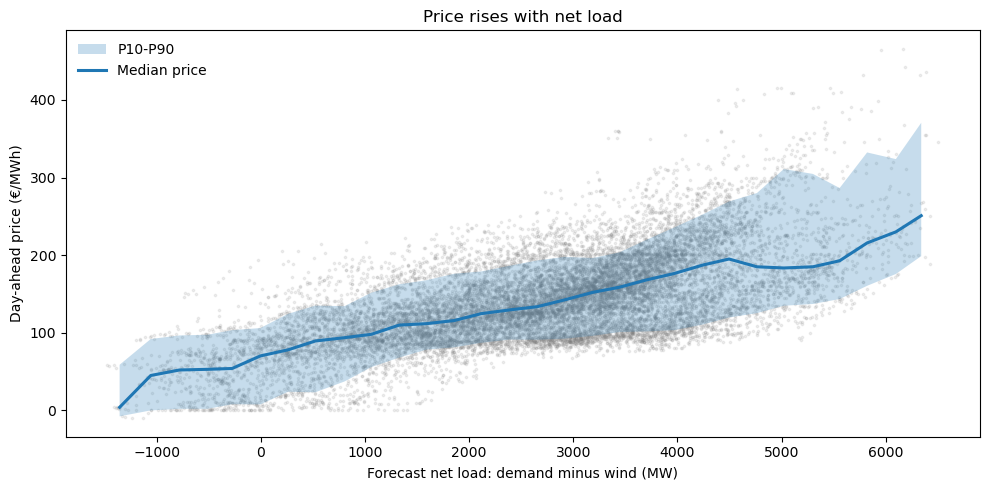

Correlation with price:
net_load_fcast    0.65
wind_fcast       -0.59
demand_basis      0.13
price_lag_48      0.52
Name: price_eur, dtype: float64


In [31]:
bins = pd.cut(fund_df["net_load_fcast"], 30)
binned = fund_df.groupby(bins, observed=True).agg(
    net_load=("net_load_fcast", "median"),
    p50=(TARGET, "median"), p10=(TARGET, lambda s: s.quantile(0.1)),
    p90=(TARGET, lambda s: s.quantile(0.9)))

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(fund_df["net_load_fcast"], fund_df[TARGET], s=3, alpha=0.12, color="grey")
ax.fill_between(binned["net_load"], binned["p10"], binned["p90"], alpha=0.25, label="P10-P90")
ax.plot(binned["net_load"], binned["p50"], lw=2.2, label="Median price")
ax.set_xlabel("Forecast net load: demand minus wind (MW)")
ax.set_ylabel("Day-ahead price (€/MWh)")
ax.set_title("Price rises with net load")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

corr = fund_df[[TARGET, "net_load_fcast", "wind_fcast", "demand_basis", "price_lag_48"]].corr()[TARGET]
print("Correlation with price:")
print(corr.drop(TARGET).round(2))

### Does adding fundamentals improve the forecast?

Three gradient boosting models, trained and tested on exactly the same rows and dates:

1. **Price history only**, as in Part 1.
2. **+ Fundamentals:** adds the wind and demand forecasts. This is the deployable model.
3. **Oracle:** uses tomorrow's *actual* wind and demand. Not deployable; it shows the most that perfect wind and demand forecasts could add.


In [32]:
train_f = fund_df[fund_df["delivery_date"] < test_start]          # train + validation
test_f = fund_df[fund_df["delivery_date"] >= test_start]

feature_sets = {
    "Price history only": FEATURES,
    "+ Fundamentals (forecasts)": FEATURES + FUND_FEATURES,
    "Oracle: actual wind & demand": FEATURES + FUND_FEATURES + ORACLE_FEATURES,}

fund_forecasts = test_f[["timestamp_utc", "timestamp_local", "delivery_date", "hour", TARGET]].copy()
fund_forecasts["naive_d1"] = test_f["price_lag_48"]
fitted = {}

for name, cols in feature_sets.items():
    fitted[name] = make_hgb(**best_params).fit(train_f[cols], train_f[TARGET])
    fund_forecasts[name] = fitted[name].predict(test_f[cols])

naive_mae_f = mean_absolute_error(fund_forecasts[TARGET], fund_forecasts["naive_d1"])
fund_results = pd.DataFrame(
    [evaluate(fund_forecasts[TARGET], fund_forecasts["naive_d1"], fund_forecasts,
              "Naive: same period yesterday", naive_mae_f)] +
    [evaluate(fund_forecasts[TARGET], fund_forecasts[name], fund_forecasts, name, naive_mae_f)
     for name in feature_sets])

base_mae = fund_results.set_index("model").loc["Price history only", "MAE"]
fund_results["MAE_change_vs_price_only_%"] = 100 * (fund_results["MAE"] / base_mae - 1)
fund_results.round(2)

,model,MAE,RMSE,peak_MAE,bias,skill_vs_naive,MAE_change_vs_price_only_%
0,Naive: same period yesterday,47.01,69.70,40.85,0.19,0.00,25.57
1,Price history only,37.44,52.83,38.41,-2.09,0.20,0.00
2,+ Fundamentals (forecasts),35.67,44.27,40.37,-26.70,0.24,-4.73
3,Oracle: actual wind & demand,33.07,41.16,38.90,-22.41,0.30,-11.66


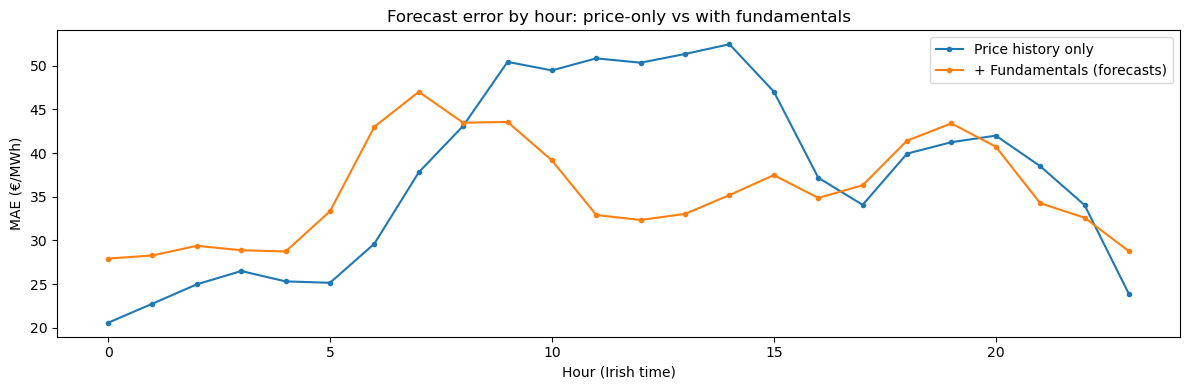

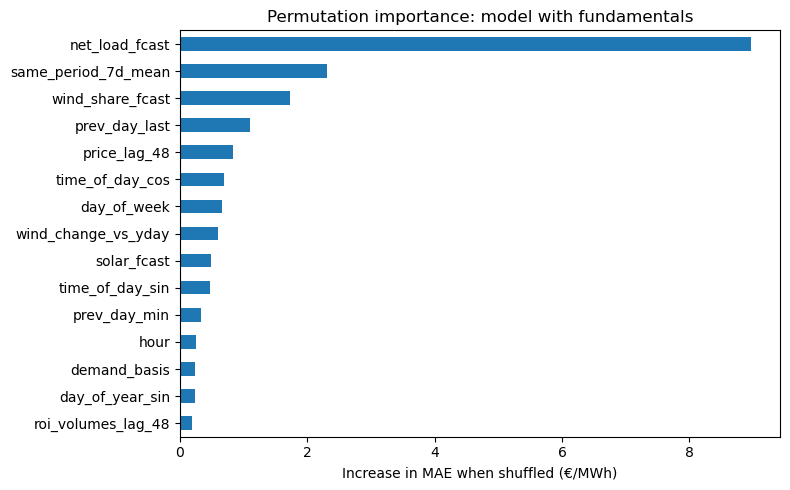

In [33]:
# Error by hour: where do fundamentals help most?
err = pd.DataFrame({
    name: (fund_forecasts[name] - fund_forecasts[TARGET]).abs().groupby(fund_forecasts["hour"]).mean()
    for name in ["Price history only", "+ Fundamentals (forecasts)"]})
ax = err.plot(figsize=(12, 4), marker="o", ms=3)
ax.set_xlabel("Hour (Irish time)")
ax.set_ylabel("MAE (€/MWh)")
ax.set_title("Forecast error by hour: price-only vs with fundamentals")
plt.tight_layout()
plt.show()

# What drives the fundamentals model?
model_cols = FEATURES + FUND_FEATURES
imp = permutation_importance(fitted["+ Fundamentals (forecasts)"], test_f[model_cols], test_f[TARGET],
                             scoring="neg_mean_absolute_error", n_repeats=5, random_state=42)
ax = (pd.Series(imp.importances_mean, index=model_cols)
        .sort_values().tail(15).plot.barh(figsize=(8, 5)))
ax.set_xlabel("Increase in MAE when shuffled (€/MWh)")
ax.set_title("Permutation importance: model with fundamentals")
plt.tight_layout()
plt.show()

### Trading value with fundamentals

In [34]:
# Re-run the battery test with the fundamentals model
fund_signals = {"Perfect foresight": TARGET,
                "+ Fundamentals (forecasts)": "+ Fundamentals (forecasts)",
                "Price history only": "Price history only",
                "Same period yesterday": "naive_d1"}

fund_pnl = pd.DataFrame({
    name: fund_forecasts.groupby("delivery_date").apply(daily_arbitrage, signal_col=col, include_groups=False)
    for name, col in fund_signals.items()})

fund_summary = pd.DataFrame({
    "total_€": fund_pnl.sum(),
    "avg_€_per_day": fund_pnl.mean(),
    "%_of_perfect": 100 * fund_pnl.sum() / fund_pnl["Perfect foresight"].sum(),
}).round(1)
fund_summary

,total_€,avg_€_per_day,%_of_perfect
Perfect foresight,10738.4,191.8,100.0
+ Fundamentals (forecasts),8933.7,159.5,83.2
Price history only,4186.0,74.8,39.0
Same period yesterday,3751.7,67.0,34.9


In [35]:
fund_forecasts.to_csv(DATA_DIR / "test_forecasts_fundamentals.csv", index=False)
fund_results.to_csv(DATA_DIR / "test_metrics_fundamentals.csv", index=False)
fund_summary.to_csv(DATA_DIR / "arbitrage_backtest_fundamentals.csv")

for local_file in ["eirgrid_fundamentals_30min.csv", "test_forecasts_fundamentals.csv",
                   "test_metrics_fundamentals.csv", "arbitrage_backtest_fundamentals.csv"]:
    with open(DATA_DIR / local_file, "rb") as f:
        container.upload_blob(f"{run_folder}/{local_file}", f, overwrite=True)
    print("Uploaded", f"{run_folder}/{local_file}")

Uploaded runs/2026-10-17/eirgrid_fundamentals_30min.csv
Uploaded runs/2026-10-17/test_forecasts_fundamentals.csv
Uploaded runs/2026-10-17/test_metrics_fundamentals.csv
Uploaded runs/2026-10-17/arbitrage_backtest_fundamentals.csv
